In [2]:
import numpy as np 
import matplotlib.pyplot as plt 
import pandas as pd 
import seaborn as sns

In [3]:
data_q1 = [1, 1.75, 2, 3, 3.25, 4]

[Text(0.5, 1.0, 'Q1 ECDF')]

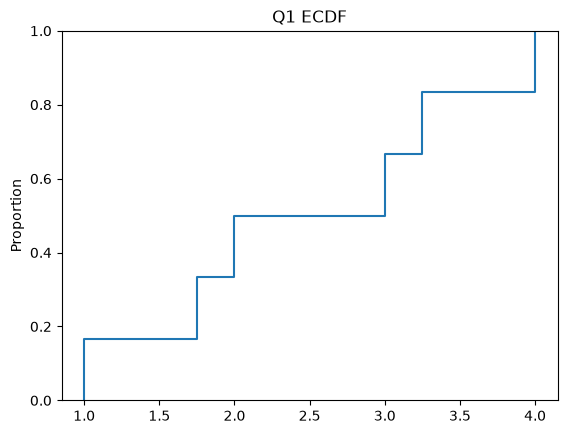

In [4]:
sns.ecdfplot(data_q1).set(title="Q1 ECDF")

In [5]:
def kde_manual_bandwidth(X,K=30, bandwidth=0.2):
    n = len(X)
    X = np.array(X)
    h_u = bandwidth
    x_grid = np.linspace( X.min()-2*h_u, X.max()+2*h_u, K) # Create a grid to plot
    I = np.abs( x_grid[:,None] - X[None,:]) < h_u # Broadcast the indicator comparison
    f_hat = np.sum(I,axis=1)/(2 * n * h_u) # Compute kde
    plt.step(x_grid,f_hat,where='mid')
    plt.fill_between(x_grid,f_hat,step='mid')
    plt.title('Uniform Kernel Density Estimator (Blocky)')
    plt.show()
    return x_grid, f_hat

def kde_silver_bandwidth(X,K=30):
    n = len(X)
    X = np.array(X)
    h_u = 1.84 * X.std() * n ** (-0.2) # Compute bandwidth
    x_grid = np.linspace( X.min()-2*h_u, X.max()+2*h_u, K) # Create a grid to plot
    I = np.abs( x_grid[:,None] - X[None,:]) < h_u # Broadcast the indicator comparison
    f_hat = np.sum(I,axis=1)/(2 * n * h_u) # Compute kde
    plt.step(x_grid,f_hat,where='mid')
    plt.fill_between(x_grid,f_hat,step='mid')
    plt.title('Uniform Kernel Density Estimator (Blocky)')
    plt.show()
    return x_grid, f_hat

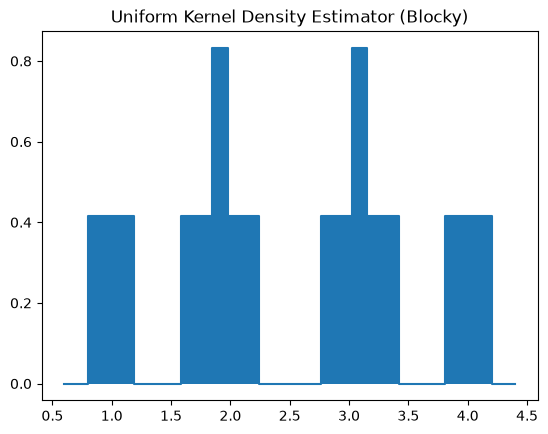

(array([0.6       , 0.73103448, 0.86206897, 0.99310345, 1.12413793,
        1.25517241, 1.3862069 , 1.51724138, 1.64827586, 1.77931034,
        1.91034483, 2.04137931, 2.17241379, 2.30344828, 2.43448276,
        2.56551724, 2.69655172, 2.82758621, 2.95862069, 3.08965517,
        3.22068966, 3.35172414, 3.48275862, 3.6137931 , 3.74482759,
        3.87586207, 4.00689655, 4.13793103, 4.26896552, 4.4       ]),
 array([0.        , 0.        , 0.41666667, 0.41666667, 0.41666667,
        0.        , 0.        , 0.        , 0.41666667, 0.41666667,
        0.83333333, 0.41666667, 0.41666667, 0.        , 0.        ,
        0.        , 0.        , 0.41666667, 0.41666667, 0.83333333,
        0.41666667, 0.41666667, 0.        , 0.        , 0.        ,
        0.41666667, 0.41666667, 0.41666667, 0.        , 0.        ]))

In [6]:
kde_manual_bandwidth(data_q1, bandwidth=0.2)

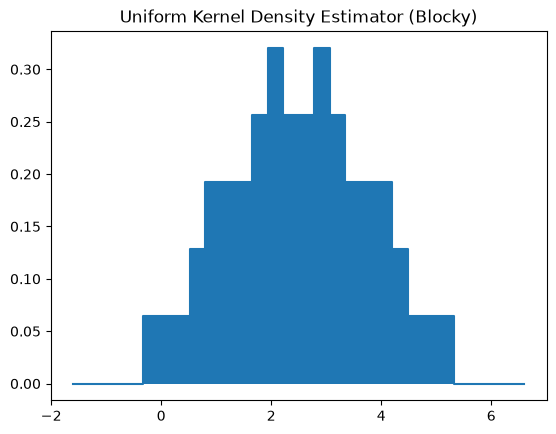

(array([-1.59833408, -1.31569035, -1.03304662, -0.75040289, -0.46775916,
        -0.18511543,  0.0975283 ,  0.38017203,  0.66281576,  0.94545949,
         1.22810322,  1.51074695,  1.79339068,  2.07603441,  2.35867814,
         2.64132186,  2.92396559,  3.20660932,  3.48925305,  3.77189678,
         4.05454051,  4.33718424,  4.61982797,  4.9024717 ,  5.18511543,
         5.46775916,  5.75040289,  6.03304662,  6.31569035,  6.59833408]),
 array([0.        , 0.        , 0.        , 0.        , 0.        ,
        0.06414366, 0.06414366, 0.06414366, 0.12828733, 0.19243099,
        0.19243099, 0.19243099, 0.25657465, 0.32071832, 0.25657465,
        0.25657465, 0.32071832, 0.25657465, 0.19243099, 0.19243099,
        0.19243099, 0.12828733, 0.06414366, 0.06414366, 0.06414366,
        0.        , 0.        , 0.        , 0.        , 0.        ]))

In [7]:
kde_silver_bandwidth(data_q1)

In [8]:
def silverman_bandwidth(X, kernel="uniform"):
    """Silverman's rule-of-thumb bandwidth. `kernel` selects the constant."""
    const = {"uniform": 1.84, "gaussian": 1.06}[kernel]
    return const * np.std(X) * len(X) ** (-0.2)


def kde_grid(X, h, pad=2.0, K=200):
    """The evaluation grid shared by every estimator below."""
    X = np.asarray(X)
    return np.linspace(X.min() - pad * h, X.max() + pad * h, K)


def uniform_kde(X, grid, h):
    """f_hat_h(x) on `grid`, uniform kernel. Pure computation, no plotting."""
    X = np.asarray(X)
    n = len(X)
    I = np.abs(grid[:, None] - X[None, :]) < h
    return I.sum(axis=1) / (2 * n * h)


def gaussian_kde(X, grid, h):
    """f_hat_h(x) on `grid`, Gaussian kernel."""
    X = np.asarray(X)
    n = len(X)
    Z = (grid[:, None] - X[None, :]) / h
    phi = np.exp(-Z**2 / 2) / np.sqrt(2 * np.pi)
    return phi.sum(axis=1) / (n * h)


def plot_density(grid, f_hat, **kwargs):
    """One shared plotting routine, reused for both single curves and bump stacks."""
    plt.step(grid, f_hat, where="mid", **kwargs)

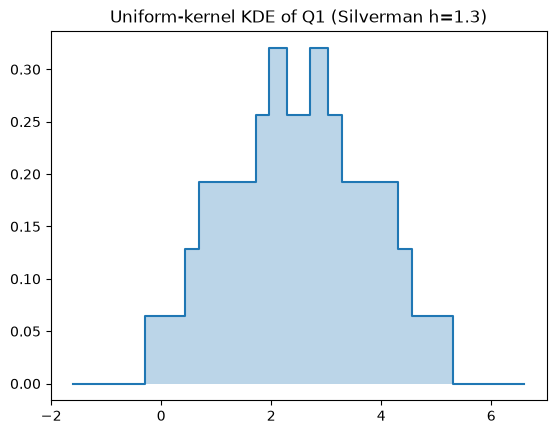

Q1: area under f_hat = 0.9987


In [9]:
# Uniform-kernel KDE on two real columns, using the shared helpers.
X = data_q1
h = silverman_bandwidth(X, "uniform")
grid = kde_grid(X, h)
f_hat = uniform_kde(X, grid, h)

plt.figure()
plot_density(grid, f_hat)
plt.fill_between(grid, f_hat, step="mid", alpha=0.3)
plt.title(f"Uniform-kernel KDE of Q1 (Silverman h={h:.3g})")
plt.show()

print(f"Q1: area under f_hat = {np.trapezoid(f_hat, grid):.4f}")

In [10]:
np.std(data_q1)

np.float64(1.0103629710818451)

In [11]:
data_q2 = [-1.0, -0.5, 0, 0.5, 1.0]
X = np.array(data_q2)
n = len(X)
h_u = 0.6
x_target = 0

f_hat_0 = np.sum(np.abs(x_target - X) < h_u) / (2 * n * h_u)
print(f_hat_0)

0.5


In [12]:
import scipy

scipy.stats.norm.cdf(0.6)

np.float64(0.7257468822499265)

In [13]:
scipy.stats.norm.cdf(-0.6)

np.float64(0.2742531177500736)

In [14]:
scipy.stats.norm.cdf(0)

np.float64(0.5)

In [15]:
scipy.stats.norm.cdf(0.1)

np.float64(0.539827837277029)

In [16]:
scipy.stats.norm.cdf(-0.1)

np.float64(0.460172162722971)

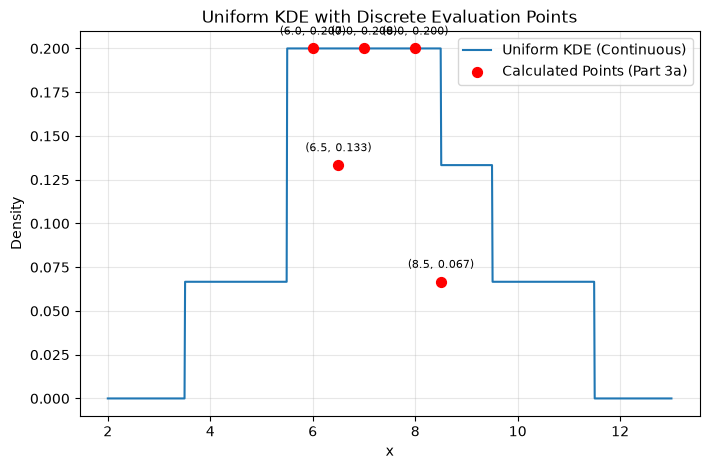

In [27]:
import matplotlib.pyplot as plt
import numpy as np

data_q3 = [5, 7, 7, 8, 10]
h = 1.5

unif = lambda z: 0.5 * (np.abs(z) < 1)


def uniform_kde_at_x(x, X, h):
    X = np.array(X)
    n = len(X)
    z = (x - X) / h
    return np.sum(unif(z)) / (n * h)


# 1. Create continuous grid for the step plot background
x_grid = np.linspace(2, 13, 1000)
y_grid = [uniform_kde_at_x(xg, data_q3, h) for xg in x_grid]

# 2. Specific evaluation points from Part 3a
x_pts = [6.0, 6.5, 7.0, 8.0, 8.5]
y_pts = [uniform_kde_at_x(xp, data_q3, h) for xp in x_pts]

# 3. Plot
plt.figure(figsize=(8, 5))
plt.plot(x_grid, y_grid, label="Uniform KDE (Continuous)", color="tab:blue")
plt.scatter(
    x_pts,
    y_pts,
    color="red",
    zorder=5,
    s=50,
    label="Calculated Points (Part 3a)",
)

# Add annotations for clarity
for x_val, y_val in zip(x_pts, y_pts):
    plt.annotate(
        f"({x_val}, {y_val:.3f})",
        (x_val, y_val),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=8,
    )

plt.xlabel("x")
plt.ylabel("Density")
plt.title("Uniform KDE with Discrete Evaluation Points")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [28]:
data_q3 = [5,7,7,8,10]

unif = lambda z: 0.5 * (np.abs(z) < 1)

def uniform_kde_at_x(x, X, h):
    X = np.array(X)
    n = len(X)
    z = (x - X) / h
    return np.sum(unif(z)) / (n * h)

for x in [6, 6.5, 7, 8, 8.5]:
    print(uniform_kde_at_x(x, data_q3, h=1.5))  # Returns 0.2

0.2
0.13333333333333333
0.2
0.2
0.06666666666666667


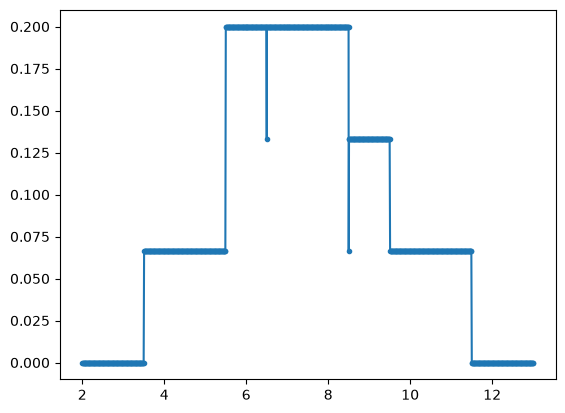

In [29]:
# Add the exact boundary points into x_grid so the plot evaluates them
critical_points = np.array([6.0, 6.5, 7.0, 8.0, 8.5])
x_grid_custom = np.sort(np.unique(np.concatenate([x_grid, critical_points])))
y_grid_custom = [uniform_kde_at_x(xg, data_q3, h) for xg in x_grid_custom]

plt.plot(x_grid_custom, y_grid_custom, marker="o", markersize=3)

In [23]:
data_q3 = [5,7,7,8,10]

gauss = lambda z: np.exp(-z**2 / 2) / np.sqrt(2 * np.pi)

def gaussian_kde_at_x(x, X, h):
    X = np.array(X)
    n = len(X)
    z = (x - X) / h
    return np.sum(gauss(z)) / (n * h)

for x in [6, 6.5, 7, 8, 8.5]:
    print(f'KDE at {x}:\n', gaussian_kde_at_x(x, data_q3, h=1.5))

KDE at 6:
 0.15116667696891303
KDE at 6.5:
 0.16865730580239766
KDE at 7:
 0.17804448100191994
KDE at 8:
 0.16744524435137584
KDE at 8.5:
 0.1506023053792177


Plug-in Bandwidth Estimated is: 1.248285


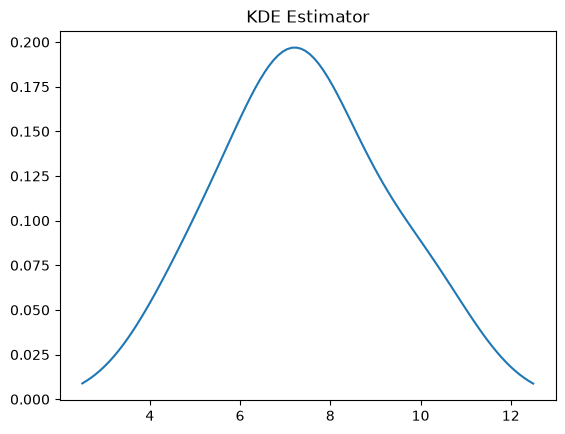

In [35]:
X = data_q3
h = 1.5
grid = kde_grid(X, h)
f_hat = gaussian_kde(X, grid, h)

def kde_g(X, h = 0.0, plot = True):
    X = np.array(X)
    gauss = lambda z: np.exp( -z**2 / 2) / np.sqrt(2 * np.pi) # Gaussian kernel
    n = len(X)
    if h == 0.0:
        h = 1.06 * X.std() * n ** (-0.2) # Compute bandwidth
        print(f'Plug-in Bandwidth Estimated is: {h:2f}')
    x_grid = np.linspace( X.min()-2*h, X.max()+2*h, 100) # Create a grid to plot
    K = gauss( (x_grid[:,None] - X[None,:])/h)/h # Broadcast the indicator
    f_hat = K.mean(axis=1)
    if plot:
        plt.plot(x_grid,f_hat)
        plt.title('KDE Estimator')
        plt.show()
    return x_grid, f_hat, h

x_grid, f_hat, h = kde_g(X)

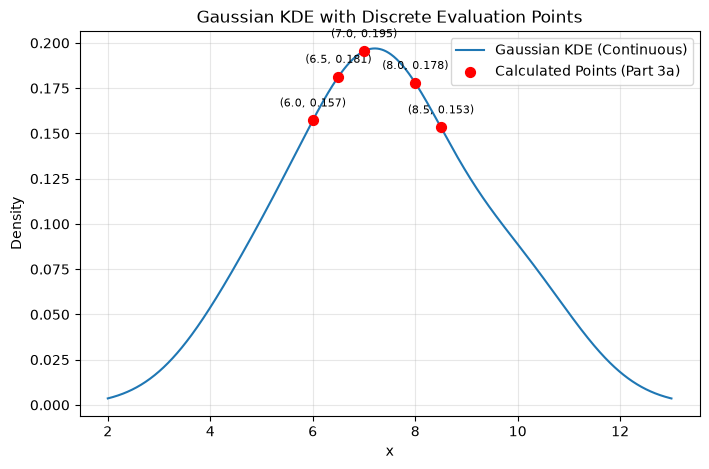

In [36]:
# 1. Create continuous grid for the step plot background
x_grid = np.linspace(2, 13, 1000)
y_grid = [gaussian_kde_at_x(xg, data_q3, h) for xg in x_grid]

# 2. Specific evaluation points from Part 3a
x_pts = [6.0, 6.5, 7.0, 8.0, 8.5]
y_pts = [gaussian_kde_at_x(xp, data_q3, h) for xp in x_pts]

# 3. Plot
plt.figure(figsize=(8, 5))
plt.plot(x_grid, y_grid, label="Gaussian KDE (Continuous)", color="tab:blue")
plt.scatter(
    x_pts,
    y_pts,
    color="red",
    zorder=5,
    s=50,
    label="Calculated Points (Part 3a)",
)

# Add annotations for clarity
for x_val, y_val in zip(x_pts, y_pts):
    plt.annotate(
        f"({x_val}, {y_val:.3f})",
        (x_val, y_val),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=8,
    )

plt.xlabel("x")
plt.ylabel("Density")
plt.title("Gaussian KDE with Discrete Evaluation Points")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [42]:
df = pd.read_csv('./data/heart_failure_clinical_records_dataset.csv')
df

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
294,62.0,0,61,1,38,1,155000.00,1.1,143,1,1,270,0
295,55.0,0,1820,0,38,0,270000.00,1.2,139,0,0,271,0
296,45.0,0,2060,1,60,0,742000.00,0.8,138,0,0,278,0
297,45.0,0,2413,0,38,0,140000.00,1.4,140,1,1,280,0


Plug-in Bandwidth Estimated is: 6.952141


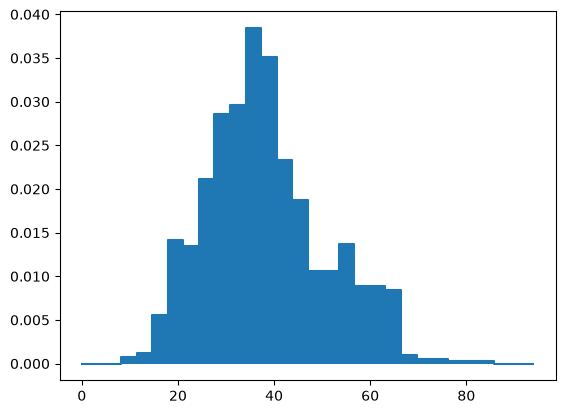

(array([ 0.09571897,  3.33049697,  6.56527498,  9.80005298, 13.03483098,
        16.26960898, 19.50438698, 22.73916499, 25.97394299, 29.20872099,
        32.44349899, 35.67827699, 38.913055  , 42.147833  , 45.382611  ,
        48.617389  , 51.852167  , 55.086945  , 58.32172301, 61.55650101,
        64.79127901, 68.02605701, 71.26083501, 74.49561302, 77.73039102,
        80.96516902, 84.19994702, 87.43472502, 90.66950303, 93.90428103]),
 array([0.        , 0.        , 0.        , 0.00072161, 0.00120268,
        0.00553233, 0.01419163, 0.01347002, 0.02116718, 0.0286238 ,
        0.02958594, 0.03848578, 0.03511827, 0.023332  , 0.01876182,
        0.01058359, 0.01058359, 0.01371056, 0.00889984, 0.00889984,
        0.00841876, 0.00096214, 0.00048107, 0.00048107, 0.00024054,
        0.00024054, 0.00024054, 0.        , 0.        , 0.        ]))

In [43]:
def kde(X,K=30):
    n = len(X)
    X = np.array(X)
    h_u = 1.84 * X.std() * n ** (-0.2) # Compute bandwidth
    print(f'Plug-in Bandwidth Estimated is: {h_u:2f}')
    x_grid = np.linspace( X.min()-2*h_u, X.max()+2*h_u, K) # Create a grid to plot
    I = np.abs( x_grid[:,None] - X[None,:]) < h_u # Broadcast the indicator
    f_hat = np.sum(I,axis=1)/(2 * n * h_u) # Compute kde
    plt.step(x_grid,f_hat,where='mid')
    plt.fill_between(x_grid,f_hat,step='mid')
    plt.show()
    return x_grid, f_hat

kde(df['ejection_fraction'])

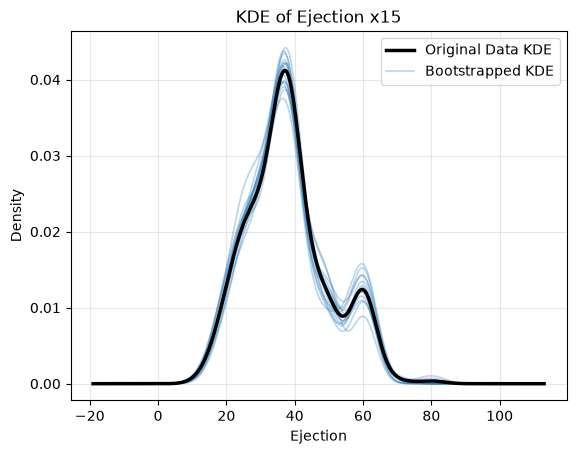

In [51]:
df['ejection_fraction'].plot.kde(
    color='black', 
    linewidth=2.5, 
    label='Original Data KDE',
    zorder=10  # Forces the black line to render on top
)

for i in range(15):
    resample = df.sample(frac=1.0, replace=True)
    resample['ejection_fraction'].plot.kde(
        color='tab:blue', 
        alpha=0.3, 
        linewidth=1.2,
        label='Bootstrapped KDE' if i == 0 else '_nolegend_'
    )

plt.title('KDE of Ejection x15')
plt.xlabel('Ejection')
plt.ylabel('Density')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()